In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# ── CARGAR DATOS ──────────────────────────────────────────────────
# Ajusta el nombre del archivo si es diferente
df = pd.read_csv('acled-data-export.csv')

print("=== COLUMNAS DEL DATASET ===")
print(list(df.columns))
print(f"\nFilas totales: {len(df):,}")
print(f"\nPrimeras filas:")
print(df.head(10))

=== COLUMNAS DEL DATASET ===
['week', 'region', 'country', 'admin1', 'event_type', 'sub_event_type', 'events', 'fatalities', 'population_exposure', 'disorder_type', 'centroid_latitude', 'centroid_longitude']

Filas totales: 68,045

Primeras filas:
         week         region     country     admin1  \
0  2019-12-28     South Asia  Bangladesh      Dhaka   
1  2019-12-28     South Asia  Bangladesh      Dhaka   
2  2019-12-28     South Asia  Bangladesh      Dhaka   
3  2019-12-28     South Asia  Bangladesh      Dhaka   
4  2019-12-28     South Asia  Bangladesh   Rajshahi   
5  2019-12-28  South America    Colombia  Antioquia   
6  2019-12-28  South America    Colombia  Antioquia   
7  2019-12-28  South America    Colombia  Atlantico   
8  2019-12-28  South America    Colombia  Atlantico   
9  2019-12-28  South America    Colombia      Cauca   

                   event_type    sub_event_type  events  fatalities  \
0  Violence against civilians            Attack       1           1   
1   

=== DATASET COLOMBIA 2020-2026 ===
Total registros: 17,491
Departamentos: 33
Período: 2020-01-04 → 2026-08-01
Total eventos: 33,336
Total fatalidades: 13,732

=== SUBTIPOS DE EVENTO ===
sub_event_type
Peaceful protest                      10813
Attack                                 7946
Armed clash                            4799
Looting/property destruction           1551
Violent demonstration                  1274
Mob violence                           1252
Abduction/forced disappearance         1225
Other                                  1130
Disrupted weapons use                  1058
Remote explosive/landmine/IED           924
Grenade                                 349
Change to group/activity                290
Air/drone strike                        257
Protest with intervention               173
Arrests                                 131
Excessive force against protesters       60
Sexual violence                          48
Shelling/artillery/missile attack        44
Agreeme

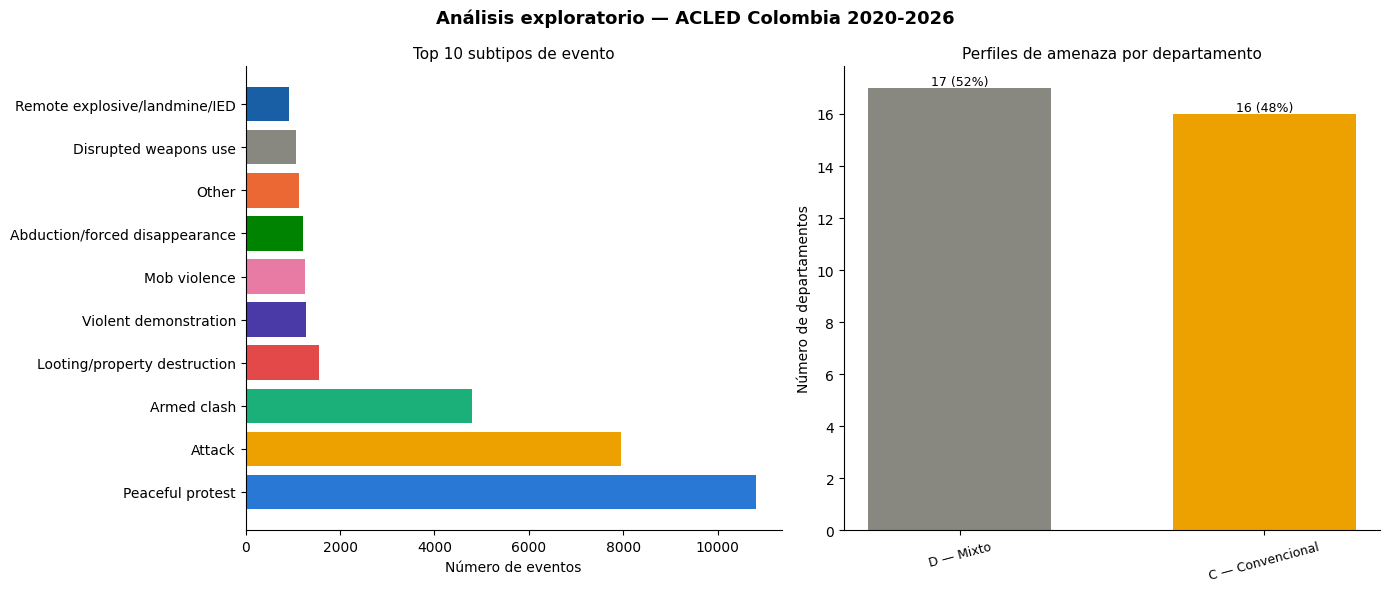

✓ Gráfica 1 guardada


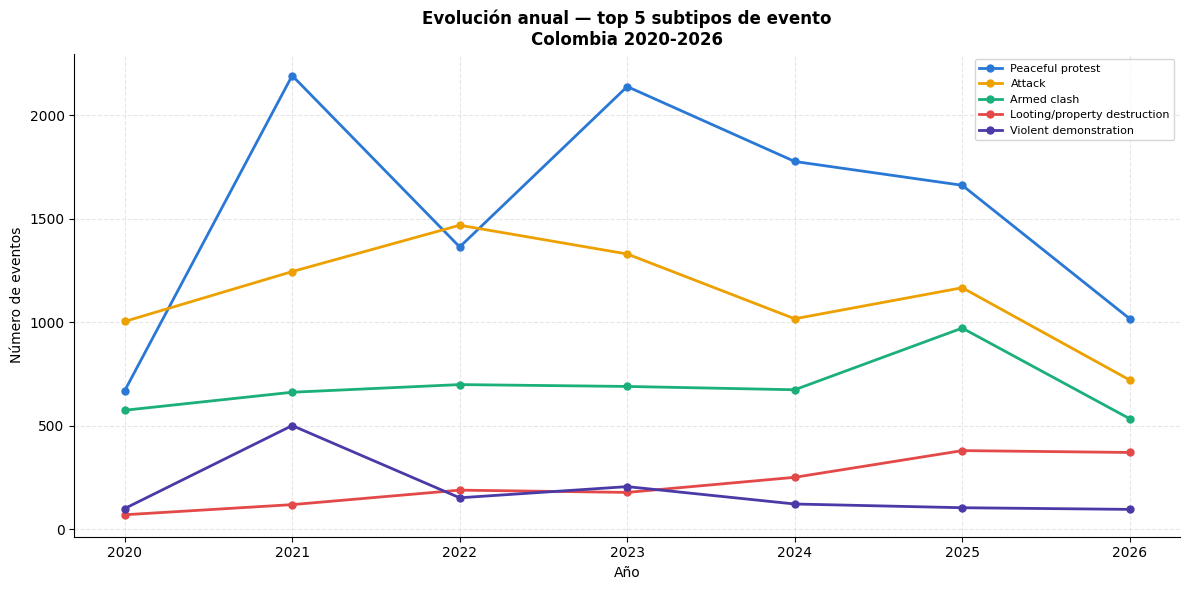

✓ Gráfica 2 guardada


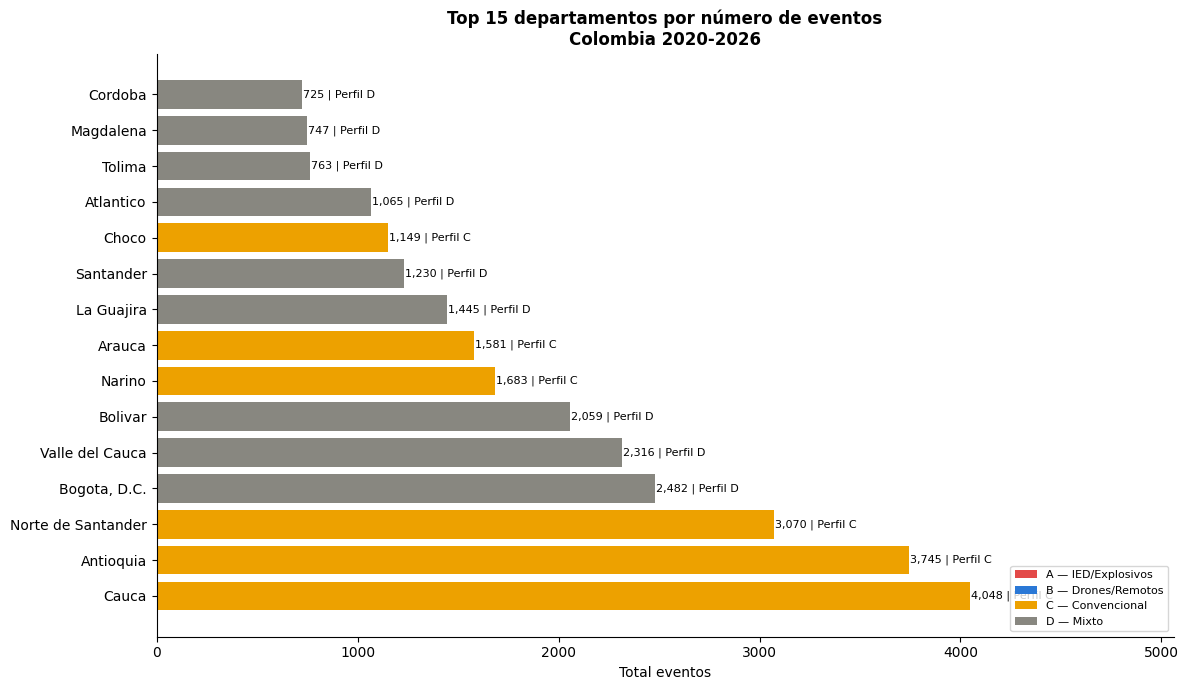

✓ Gráfica 3 guardada

=== RESUMEN PARA EL DOCUMENTO ===
Total registros Colombia 2020-2026: 17,491
Departamentos con datos: 33
Total eventos registrados: 33,336
Total fatalidades: 13,732
Período: 2020-01-04 → 2026-08-01

Distribución de perfiles de amenaza:
  Perfil D: 17 departamentos (52%)
  Perfil C: 16 departamentos (48%)

Subtipos más frecuentes:
sub_event_type
Peaceful protest                10813
Attack                           7946
Armed clash                      4799
Looting/property destruction     1551
Violent demonstration            1274
Name: events, dtype: int64

Valores faltantes en columnas clave:
admin1            0
event_type        0
sub_event_type    0
events            0
fatalities        0
dtype: int64

✓ Análisis completado. Descarga las 3 imágenes PNG del panel izquierdo.


In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# ── 1. CARGAR Y FILTRAR COLOMBIA ──────────────────────────────────
df = pd.read_csv('acled-data-export.csv')
df = df[df['country'] == 'Colombia'].copy()
df['week'] = pd.to_datetime(df['week'])
df = df[df['week'] >= '2020-01-01']

print("=== DATASET COLOMBIA 2020-2026 ===")
print(f"Total registros: {len(df):,}")
print(f"Departamentos: {df['admin1'].nunique()}")
print(f"Período: {df['week'].min().date()} → {df['week'].max().date()}")
print(f"Total eventos: {df['events'].sum():,.0f}")
print(f"Total fatalidades: {df['fatalities'].sum():,.0f}")

# ── 2. SUBTIPOS DE EVENTO ─────────────────────────────────────────
print("\n=== SUBTIPOS DE EVENTO ===")
subtipos = df.groupby('sub_event_type')['events'].sum().sort_values(ascending=False)
print(subtipos)

# ── 3. CONSTRUIR VARIABLE OBJETIVO ────────────────────────────────
mapa_perfil = {
    'Remote explosive/landmine/IED': 'A',
    'Grenade': 'A',
    'Air/drone strike': 'B',
    'Suicide bomb': 'A',
    'Armed clash': 'C',
    'Attack': 'C',
    'Shooting': 'C',
    'Abduction/forced disappearance': 'C',
    'Looting/property destruction': 'C',
    'Mob violence': 'D',
    'Peaceful protest': 'D',
    'Excessive force against protesters': 'D',
    'Arrests': 'D',
    'Government regains territory': 'D',
    'Non-state actor overtakes territory': 'D',
    'Disrupted weapons use': 'C',
    'Chemical weapon': 'A',
}
df['perfil_base'] = df['sub_event_type'].map(mapa_perfil).fillna('D')

# Agregar por departamento
agg = df.groupby(['admin1', 'perfil_base'])['events'].sum().unstack(fill_value=0)
agg['total'] = agg.sum(axis=1)
for col in ['A', 'B', 'C', 'D']:
    if col not in agg.columns:
        agg[col] = 0
    agg[f'pct_{col}'] = agg[col] / agg['total']

def asignar_perfil(row):
    perfiles = {k: row.get(f'pct_{k}', 0) for k in ['A','B','C','D']}
    max_pct = max(perfiles.values())
    if max_pct >= 0.50:
        return max(perfiles, key=perfiles.get)
    return 'D'

agg['perfil_amenaza'] = agg.apply(asignar_perfil, axis=1)

print("\n=== PERFILES DE AMENAZA POR DEPARTAMENTO ===")
print(agg['perfil_amenaza'].value_counts())
print("\nDetalle por departamento:")
print(agg[['total', 'pct_A', 'pct_B', 'pct_C', 'pct_D', 'perfil_amenaza']].round(3))

# ── 4. GRÁFICA 1 — SUBTIPOS DE EVENTO ────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('Análisis exploratorio — ACLED Colombia 2020-2026',
             fontsize=13, fontweight='bold')

top_subtipos = subtipos.head(10)
colores = ['#2a78d6','#eda100','#1baf7a','#e34948','#4a3aa7',
           '#e87ba4','#008300','#eb6834','#888780','#185FA5']
axes[0].barh(top_subtipos.index, top_subtipos.values,
             color=colores[:len(top_subtipos)])
axes[0].set_title('Top 10 subtipos de evento', fontsize=11)
axes[0].set_xlabel('Número de eventos')
axes[0].spines['top'].set_visible(False)
axes[0].spines['right'].set_visible(False)

# Gráfica 2 — Distribución de perfiles
perfil_counts = agg['perfil_amenaza'].value_counts()
colores_perfil = {'A':'#e34948','B':'#2a78d6','C':'#eda100','D':'#888780'}
etiquetas = {'A':'A — IED/Explosivos','B':'B — Drones/Remotos',
             'C':'C — Convencional','D':'D — Mixto'}
colores_bar = [colores_perfil.get(p,'#888780') for p in perfil_counts.index]
labels_disp = [etiquetas.get(p,p) for p in perfil_counts.index]
bars = axes[1].bar(labels_disp, perfil_counts.values,
                   color=colores_bar, width=0.6)
axes[1].set_title('Perfiles de amenaza por departamento', fontsize=11)
axes[1].set_ylabel('Número de departamentos')
axes[1].tick_params(axis='x', rotation=15, labelsize=9)
for bar, v in zip(bars, perfil_counts.values):
    pct = v / len(agg) * 100
    axes[1].text(bar.get_x() + bar.get_width()/2,
                bar.get_height() + 0.1,
                f'{v} ({pct:.0f}%)', ha='center', fontsize=9)
axes[1].spines['top'].set_visible(False)
axes[1].spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('grafica1_perfiles.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ Gráfica 1 guardada")

# ── 5. GRÁFICA 2 — EVOLUCIÓN TEMPORAL ────────────────────────────
df['anio'] = df['week'].dt.year
evol = df.groupby(['anio', 'sub_event_type'])['events'].sum().unstack(fill_value=0)
top5 = subtipos.head(5).index
fig2, ax2 = plt.subplots(figsize=(12, 6))
for i, col in enumerate(top5):
    if col in evol.columns:
        ax2.plot(evol.index, evol[col], marker='o', linewidth=2,
                color=colores[i], label=col, markersize=5)
ax2.set_title('Evolución anual — top 5 subtipos de evento\nColombia 2020-2026',
              fontsize=12, fontweight='bold')
ax2.set_xlabel('Año')
ax2.set_ylabel('Número de eventos')
ax2.legend(fontsize=8)
ax2.grid(True, alpha=0.3, linestyle='--')
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('grafica2_evolucion.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ Gráfica 2 guardada")

# ── 6. GRÁFICA 3 — TOP DEPARTAMENTOS ─────────────────────────────
total_dept = df.groupby('admin1')['events'].sum().sort_values(ascending=False).head(15)
perfil_dept = agg['perfil_amenaza'].to_dict()
colores_dept = [colores_perfil.get(perfil_dept.get(d,'D'),'#888780')
               for d in total_dept.index]
fig3, ax3 = plt.subplots(figsize=(12, 7))
ax3.barh(total_dept.index, total_dept.values, color=colores_dept)
ax3.set_title('Top 15 departamentos por número de eventos\nColombia 2020-2026',
              fontsize=12, fontweight='bold')
ax3.set_xlabel('Total eventos')
for i, (dept, v) in enumerate(total_dept.items()):
    perfil = perfil_dept.get(dept, 'D')
    ax3.text(v + 5, i, f'{v:,.0f} | Perfil {perfil}',
             va='center', fontsize=8)
from matplotlib.patches import Patch
leyenda = [Patch(facecolor=colores_perfil[k], label=etiquetas[k])
           for k in ['A','B','C','D']]
ax3.legend(handles=leyenda, loc='lower right', fontsize=8)
ax3.spines['top'].set_visible(False)
ax3.spines['right'].set_visible(False)
ax3.set_xlim(0, total_dept.max() * 1.25)
plt.tight_layout()
plt.savefig('grafica3_departamentos.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ Gráfica 3 guardada")

# ── 7. RESUMEN FINAL ──────────────────────────────────────────────
print("\n=== RESUMEN PARA EL DOCUMENTO ===")
print(f"Total registros Colombia 2020-2026: {len(df):,}")
print(f"Departamentos con datos: {df['admin1'].nunique()}")
print(f"Total eventos registrados: {df['events'].sum():,.0f}")
print(f"Total fatalidades: {df['fatalities'].sum():,.0f}")
print(f"Período: {df['week'].min().date()} → {df['week'].max().date()}")
print(f"\nDistribución de perfiles de amenaza:")
for perfil, n in agg['perfil_amenaza'].value_counts().items():
    pct = n / len(agg) * 100
    print(f"  Perfil {perfil}: {n} departamentos ({pct:.0f}%)")
print(f"\nSubtipos más frecuentes:")
print(subtipos.head(5))
print(f"\nValores faltantes en columnas clave:")
print(df[['admin1','event_type','sub_event_type','events','fatalities']].isnull().sum())
print("\n✓ Análisis completado. Descarga las 3 imágenes PNG del panel izquierdo.")